# OpenADMET Blind Challenge: Predicting CYP Inhibition
The next OpenADMET blind challenge focuses on predicting Cytochrome P450 (CYP) inhibition. CYP enzymes are the primary drivers of xenobiotic metabolism, and unexpected CYP inhibition can derail drug discovery programs through unpredictable drug-drug interactions. The goal of this challenge is to develop predictive models that can accurately forecast CYP inhibition, thereby aiding in the design of safer and more effective drugs.

This heme-containing superfamily is responsible for the biotransformation of the vast majority of marketed small-molecule drugs and contains dozens of human isoforms with overlapping and complementary substrate scopes. This flexibility is exactly what makes them so central to xenobiotic metabolism and makes their collective behavior difficult to predict  

https://openadmet.ghost.io/announcing-openadmets-cyp-inhibition-blind-challenge/  

https://openadmet.ghost.io/halfway-through-the-openadmet-cyp-challenge/  

https://huggingface.co/spaces/openadmet/cyp-chal  


This challenge is split into three related tracks.

1. Direct Inhibition Track (Regression)
Predict the direct-inhibition (pIC50) for all 4 isoforms (CYP3A4, CYP2C9, CYP2D6, CYP1A2) across the 750-compound test set (4 continuous regression targets per compound).

Soft-Threshold Scoring: Low-activity compounds (pIC50 < 4) fall below the lowest tested assay dose and carry higher experimental noise. To avoid penalizing models unfairly, we introduce Soft-Threshold Relative Absolute Error (ST-RAE). Error is measured as the distance between the predicted value and the credible interval bound of the fitted dose-response curve; predictions falling anywhere inside the credible interval incur zero error.
Primary Evaluation Metric: Macro-Averaged Soft-Threshold RAE (MA-ST-RAE) across all four endpoints. Secondary metrics (MAE, R², Spearman ρ, Kendall's τ) are also reported with 1,000-sample bootstrap confidence intervals.
2. Time-Dependent Inhibition Track (Classification)
Classify whether a compound exhibits significant time-dependent inhibition (boolean True/False label). This mirrors real-world drug discovery workflows where positive calls trigger follow-up kinetic studies.

Target Isoforms: Evaluated on CYP3A4 and CYP2D6 only (where TDI phenomena are clinically prominent).
Primary Evaluation Metric: Matthews Correlation Coefficient (MCC), ideal for imbalanced, threshold-based classification labels.
Label Definition: Positive means the TDI-arm IC50 shift exceeds 2-fold relative to direct inhibition, including inferred positives among low-activity compounds where a shift can't be measured directly. See the FAQ for the full labeling rules.enge

Submit Your Predictions
New to the challenge? See the CYP Challenge Tutorial for a step-by-step walkthrough of data loading, model building, and preparing your submission. The tutorial repository also includes a validation script to check your files before uploading. Training and test sets are available on the HuggingFace dataset page.

Regression Track
Submit a .parquet or .csv file with exactly 750 rows and 6 columns — a numeric prediction for all 4 CYP isoforms (direct inhibition), for every compound, no NaN or inf:

Column Name	Type	Description
SMILES	string	SMILES string for the compound
Molecule_Name	string	Unique compound identifier
CYP1A2_pIC50_direct_inhibition	float	Predicted direct-inhibition pIC50 for CYP1A2
CYP2C9_pIC50_direct_inhibition	float	Predicted direct-inhibition pIC50 for CYP2C9
CYP2D6_pIC50_direct_inhibition	float	Predicted direct-inhibition pIC50 for CYP2D6
CYP3A4_pIC50_direct_inhibition	float	Predicted direct-inhibition pIC50 for CYP3A4


Classification Track
Submit a .parquet or .csv file with exactly 750 rows and 4 columns — a bool prediction for TDI for CYP2D6 and CYP3A4, for every compound:

Column Name	Type	Description
SMILES	string	SMILES string for the compound
Molecule_Name	string	Unique compound identifier
CYP2D6_is_TDI	bool	Predicted time-dependent inhibition call for CYP2D6 (True/False or 1/0)
CYP3A4_is_TDI	bool	Predicted time-dependent inhibition call for CYP3A4 (True/False or 1/0)


                                                           

## Feature Generation

In [1]:
from __future__ import annotations
import warnings, time
from dataclasses import dataclass, field
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import math

from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Descriptors, Descriptors3D, AllChem, rdFingerprintGenerator, rdMolDescriptors, Draw
from rdkit.ML.Cluster import Butina
from scipy.stats import spearmanr, kendalltau
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
import io

from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import GroupKFold
from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, f1_score, roc_auc_score, confusion_matrix, mean_absolute_error
from sklearn.model_selection import cross_validate,cross_val_score, KFold
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.decomposition import PCA
import optuna
import shap

In [3]:
sns.set_style("whitegrid")
sns.set_style("whitegrid")
sns.set_context("notebook")

In [4]:
train_df = pd.read_csv("hf://datasets/openadmet/cyp-challenge-train-test/cyp-challenge-TRAIN_inhibition.csv")

In [5]:
train_feature_df = pd.read_csv("Feature_train.csv")
train_finderprint_df = pd.read_csv("Fingerprint_train.csv")

In [6]:
CYP_ISOFORMS = ["CYP1A2", "CYP2C9", "CYP2D6", "CYP3A4"]

(1412, 2268)
Removing features with zero variance
(1412, 2246)
Removing feature with less then 0.1 correlation
(1412, 29)
Cross-Validation Performance:
Training RMSE: 0.2103 (±0.0060)
Training R²: 0.9592 (±0.0014)
Validation RMSE: 0.9488 (±0.0661)
Validation R²: 0.1663 (±0.0514)

Final Test Performance:
RMSE: 0.9343
R²: 0.0962


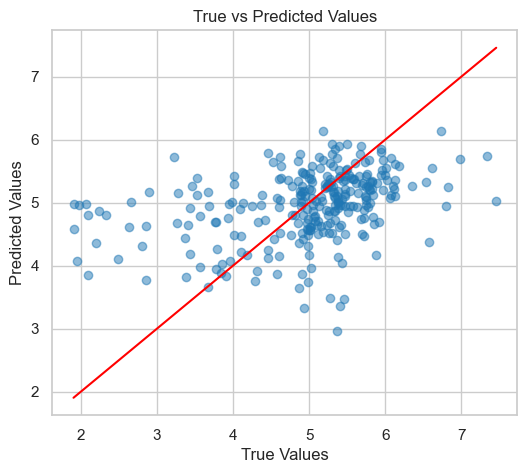

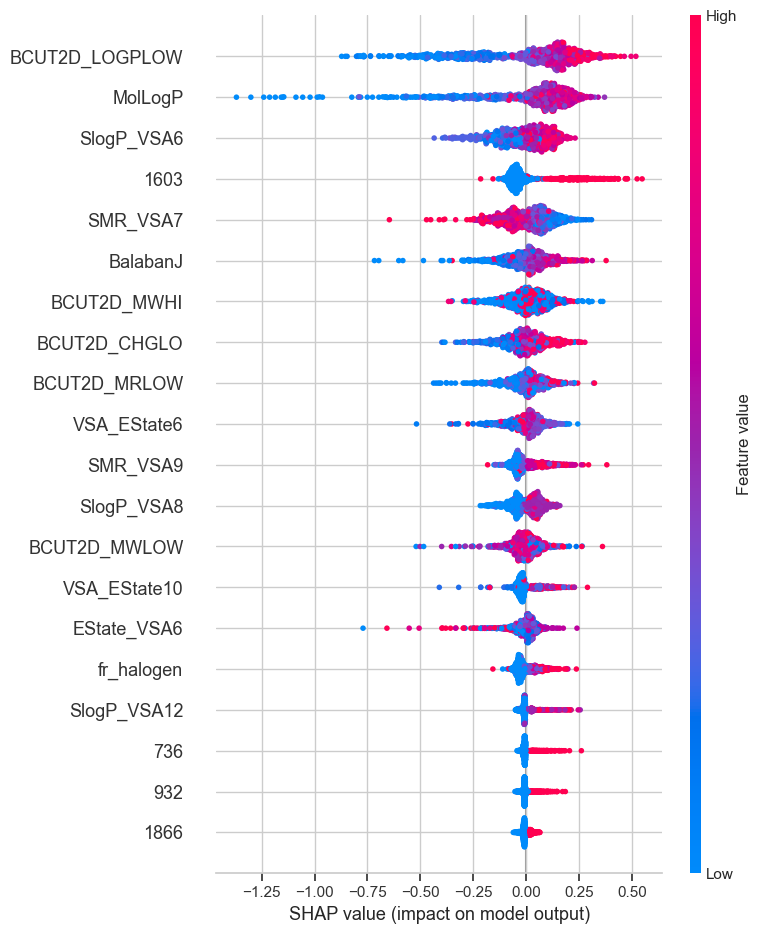

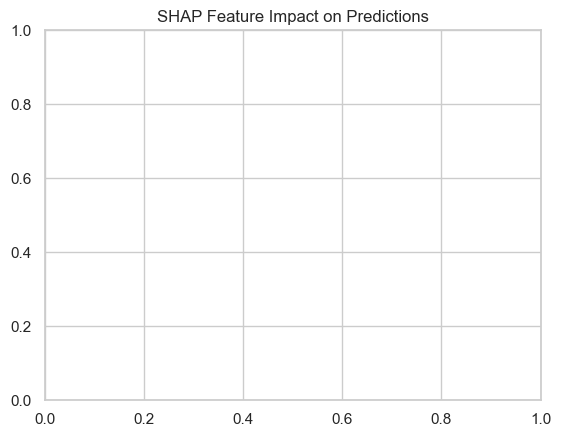



(1285, 2268)
Removing features with zero variance
(1285, 2247)
Removing feature with less then 0.1 correlation
(1285, 68)
Cross-Validation Performance:
Training RMSE: 0.1016 (±0.0038)
Training R²: 0.9836 (±0.0013)
Validation RMSE: 0.6835 (±0.0487)
Validation R²: 0.2578 (±0.0426)

Final Test Performance:
RMSE: 0.6695
R²: 0.1553


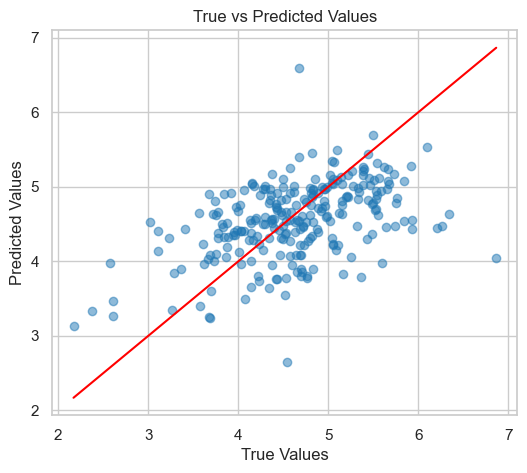

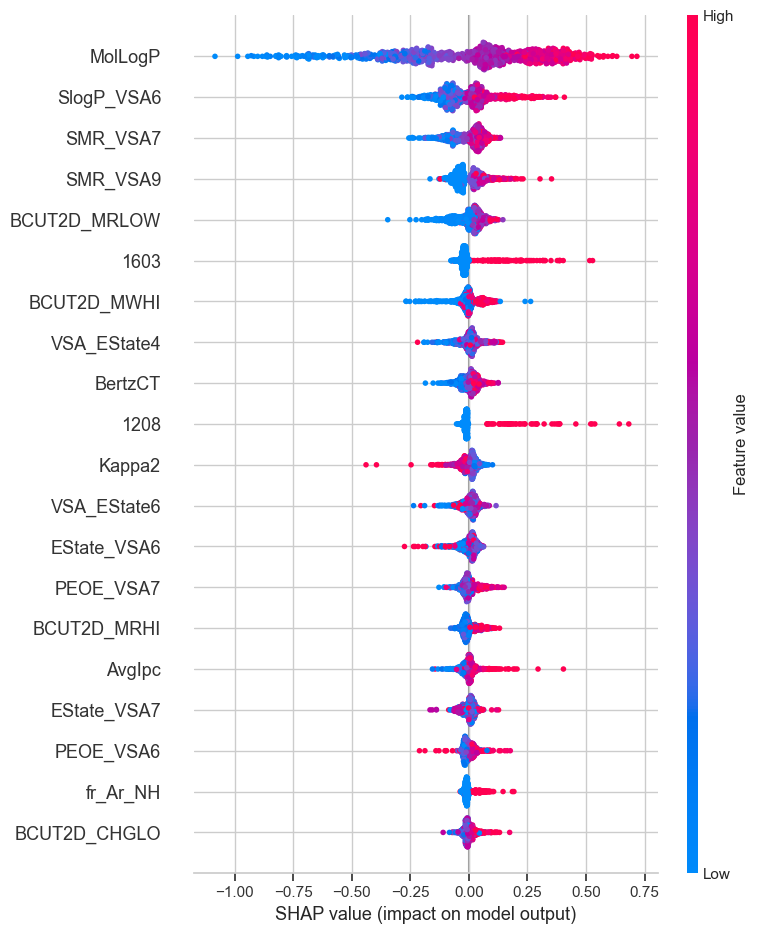

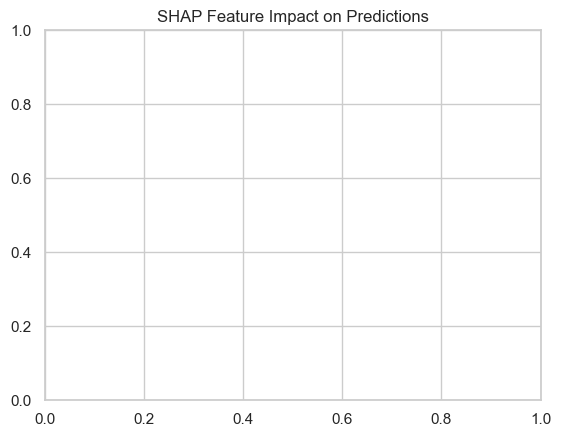



(1493, 2268)
Removing features with zero variance
(1493, 2250)
Removing feature with less then 0.1 correlation
(1493, 21)
Cross-Validation Performance:
Training RMSE: 0.3600 (±0.0268)
Training R²: 0.8461 (±0.0222)
Validation RMSE: 0.9128 (±0.0259)
Validation R²: 0.0076 (±0.0717)

Final Test Performance:
RMSE: 0.9224
R²: -0.0518


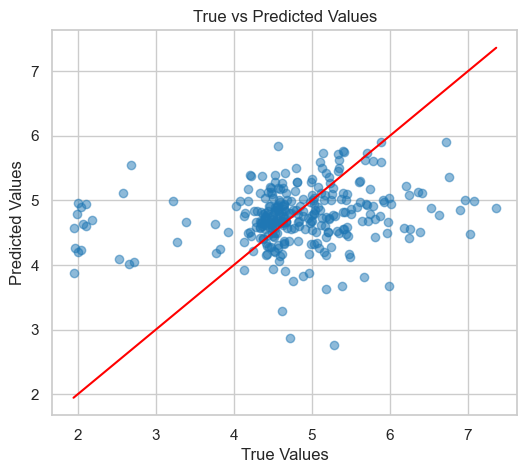

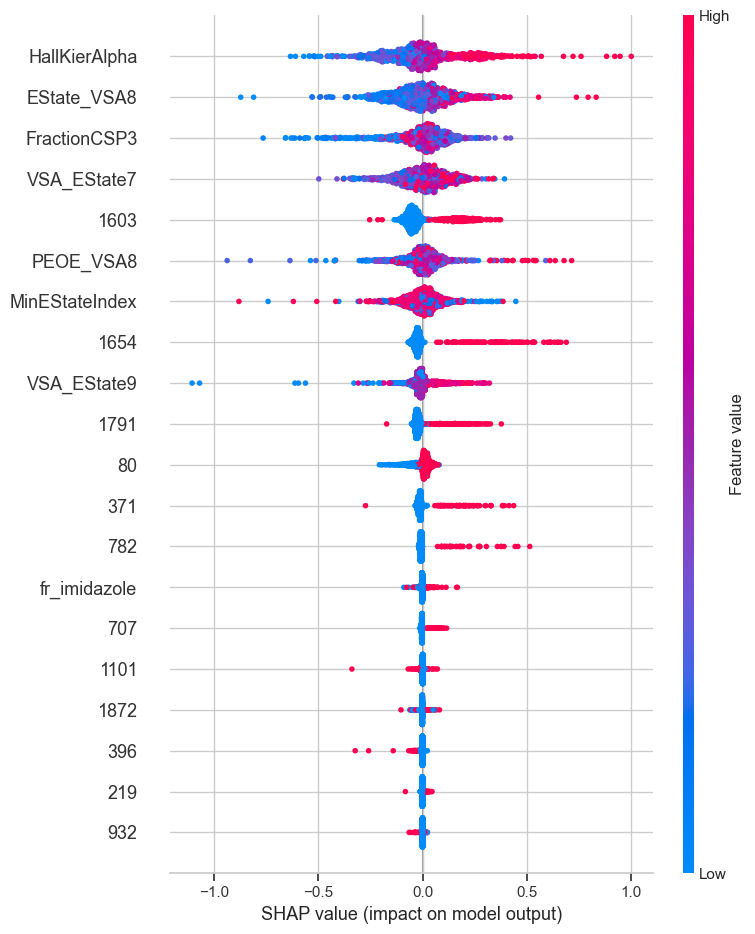

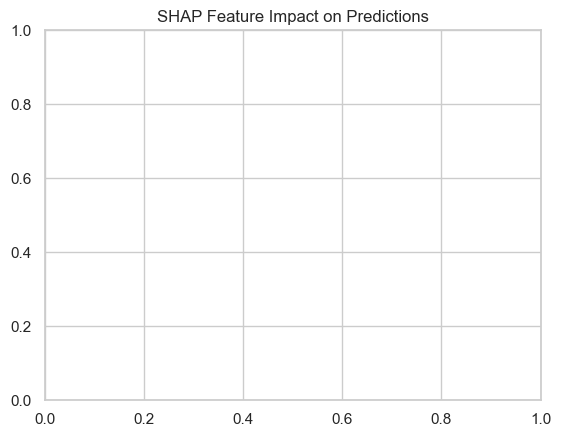



(2335, 2268)
Removing features with zero variance
(2335, 2250)
Removing feature with less then 0.1 correlation
(2335, 74)
Cross-Validation Performance:
Training RMSE: 0.2036 (±0.0100)
Training R²: 0.9645 (±0.0034)
Validation RMSE: 0.7798 (±0.0171)
Validation R²: 0.4794 (±0.0194)

Final Test Performance:
RMSE: 0.7873
R²: 0.5200


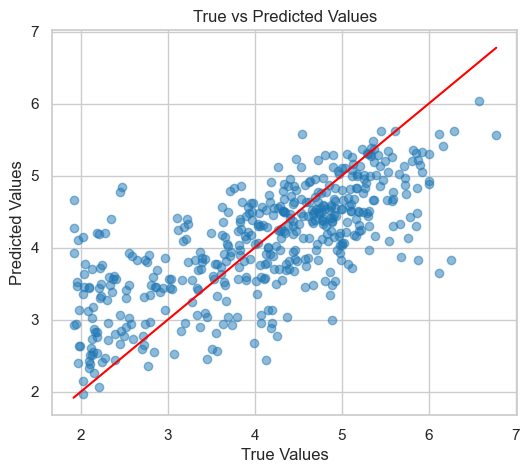

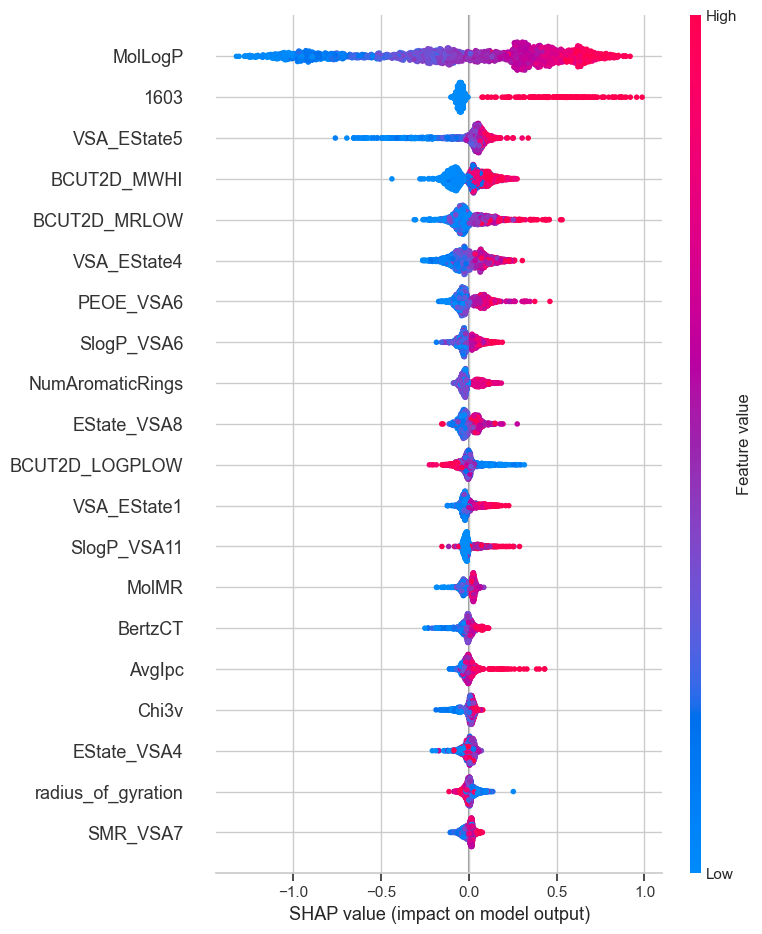

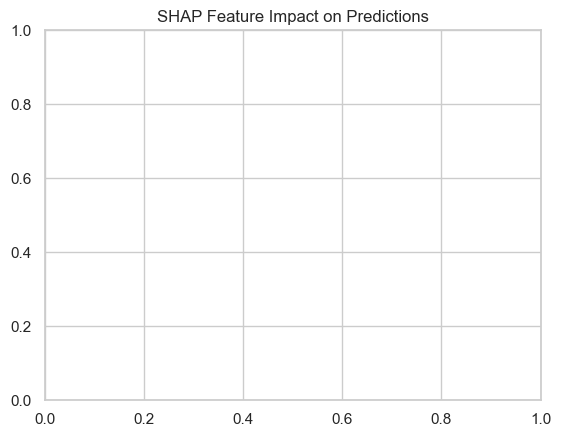

In [53]:
for i in CYP_ISOFORMS:
    cols = ["SMILES",f"{i}_pIC50_direct_inhibition"]    
    model_df = train_df[cols].copy()
    model_df.dropna(inplace=True)
    model_df = model_df.merge(train_feature_df,on="SMILES")
    model_df.drop("Molecule_Name",axis=1,inplace=True)
    model_df = model_df.merge(train_finderprint_df,on="SMILES")
    model_df.set_index("SMILES",inplace=True)
    
    print(model_df.shape)
    print("Removing features with zero variance")
    data = model_df.loc[:, model_df.var() !=0] 
    print(data.shape)
    print("Removing feature with less then 0.1 correlation")
    cor = data.corr()[f"{i}_pIC50_direct_inhibition"]
    data = data[cor[cor>0.1].index]
    print(data.shape)

    X = data.drop([f"{i}_pIC50_direct_inhibition"],axis=1)
    y =data[f"{i}_pIC50_direct_inhibition"].values
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    scaler = StandardScaler().fit(X_train.values)
    X_train = pd.DataFrame(scaler.transform(X_train.values),  columns=X.columns)
    X_test = pd.DataFrame(scaler.transform(X_test.values), columns=X.columns)

    model = xgb.XGBRegressor(objective='reg:squarederror',  n_estimators=1000, learning_rate=0.01, random_state=42)
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    scoring = {'rmse': 'neg_root_mean_squared_error','r2': 'r2'}
    
    cv_results = cross_validate(model, X_train,y_train, cv=cv, scoring=scoring, return_train_score=True, return_estimator=True)
    
    train_rmse_mean = -cv_results['train_rmse'].mean()
    train_rmse_std = cv_results['train_rmse'].std()
    train_r2_mean = cv_results['train_r2'].mean()
    train_r2_std = cv_results['train_r2'].std()
    test_rmse_mean = -cv_results['test_rmse'].mean()
    test_rmse_std = cv_results['test_rmse'].std()
    test_r2_mean = cv_results['test_r2'].mean()
    test_r2_std = cv_results['test_r2'].std()
    
    print("Cross-Validation Performance:")
    print(f"Training RMSE: {train_rmse_mean:.4f} (±{train_rmse_std:.4f})")
    print(f"Training R²: {train_r2_mean:.4f} (±{train_r2_std:.4f})")
    print(f"Validation RMSE: {test_rmse_mean:.4f} (±{test_rmse_std:.4f})")
    print(f"Validation R²: {test_r2_mean:.4f} (±{test_r2_std:.4f})\n")
    
    model.fit(X_train, y_train)
    y_pred_test = model.predict(X_test)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    r2_test = r2_score(y_test, y_pred_test)
    
    print("Final Test Performance:")
    print(f"RMSE: {rmse_test:.4f}")
    print(f"R²: {r2_test:.4f}")  

    plt.figure(figsize=(6, 5))
    plt.scatter(y_test, y_pred_test, alpha=0.5)
    plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red')
    plt.xlabel("True Values")
    plt.ylabel("Predicted Values")
    plt.title("True vs Predicted Values")
    plt.show()
    explainer = shap.Explainer(model)
    shap_values = explainer(X_train)
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_train)
    plt.title("SHAP Feature Impact on Predictions")
    plt.show()
    print("\n")

In [7]:
from similarity_split import similarity_train_test_split

(1412, 2268)
Removing features with zero variance
(1412, 2246)
Removing feature with less then 0.1 correlation
(1412, 29)


C:\Users\shasa\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\shasa\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\shasa\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\shasa\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

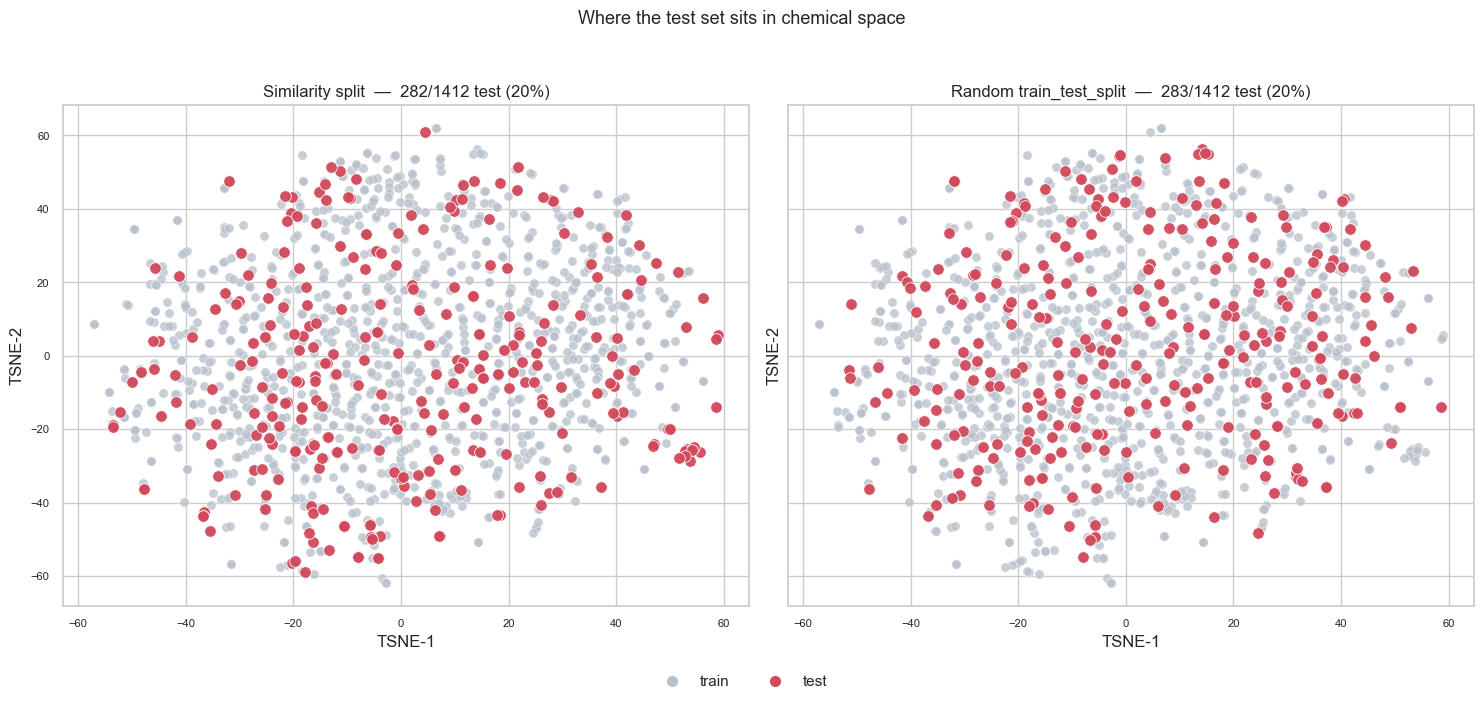

Cross-Validation Performance:
Training RMSE: 0.2365 (±0.0109)
Training R²: 0.9473 (±0.0047)
Validation RMSE: 0.9541 (±0.0560)
Validation R²: 0.1403 (±0.0554)

Final Test Performance:
RMSE: 0.9530
R²: 0.1282


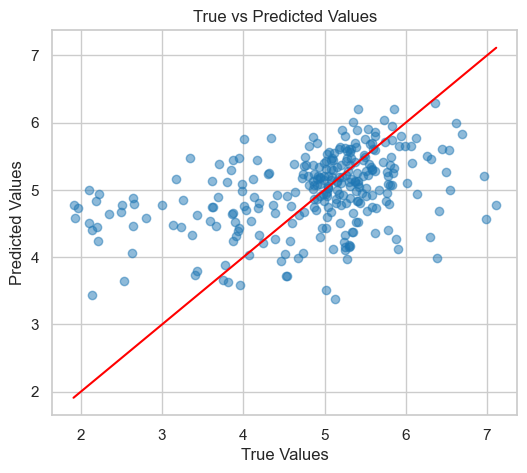

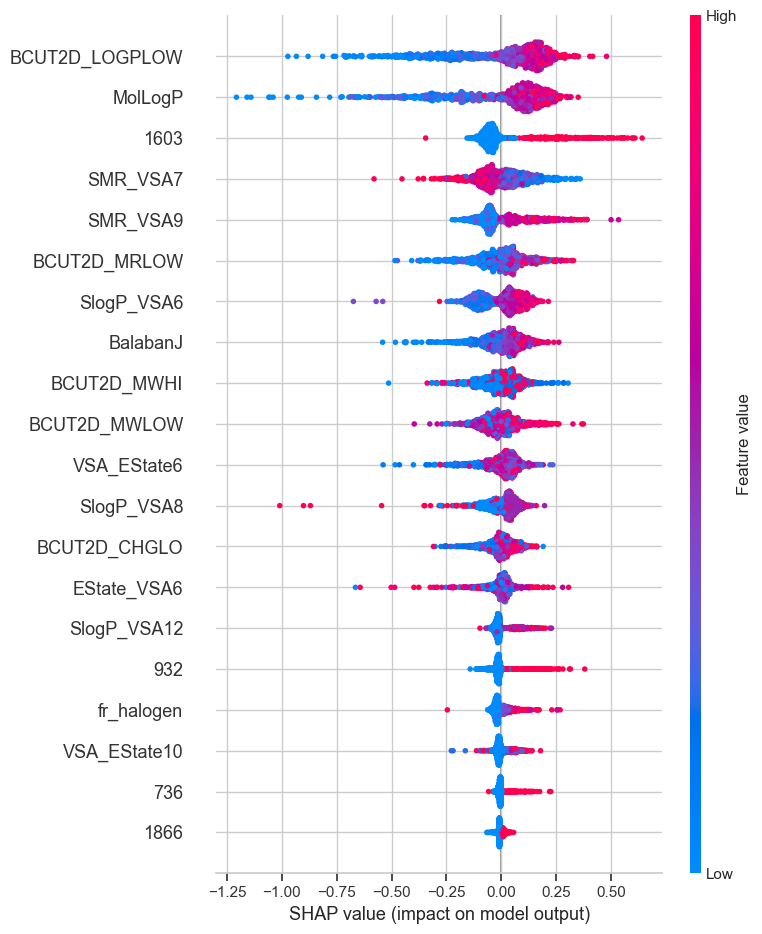

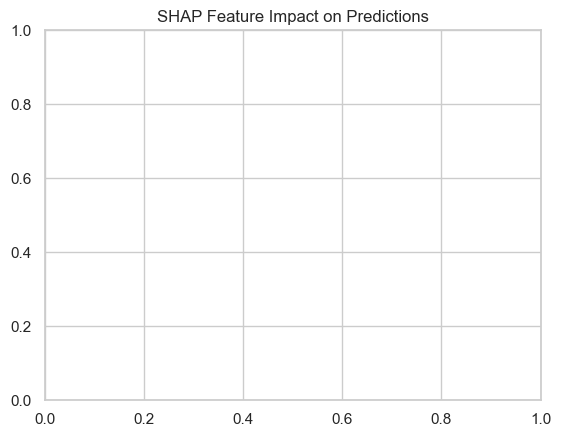



(1285, 2268)
Removing features with zero variance
(1285, 2247)
Removing feature with less then 0.1 correlation
(1285, 68)


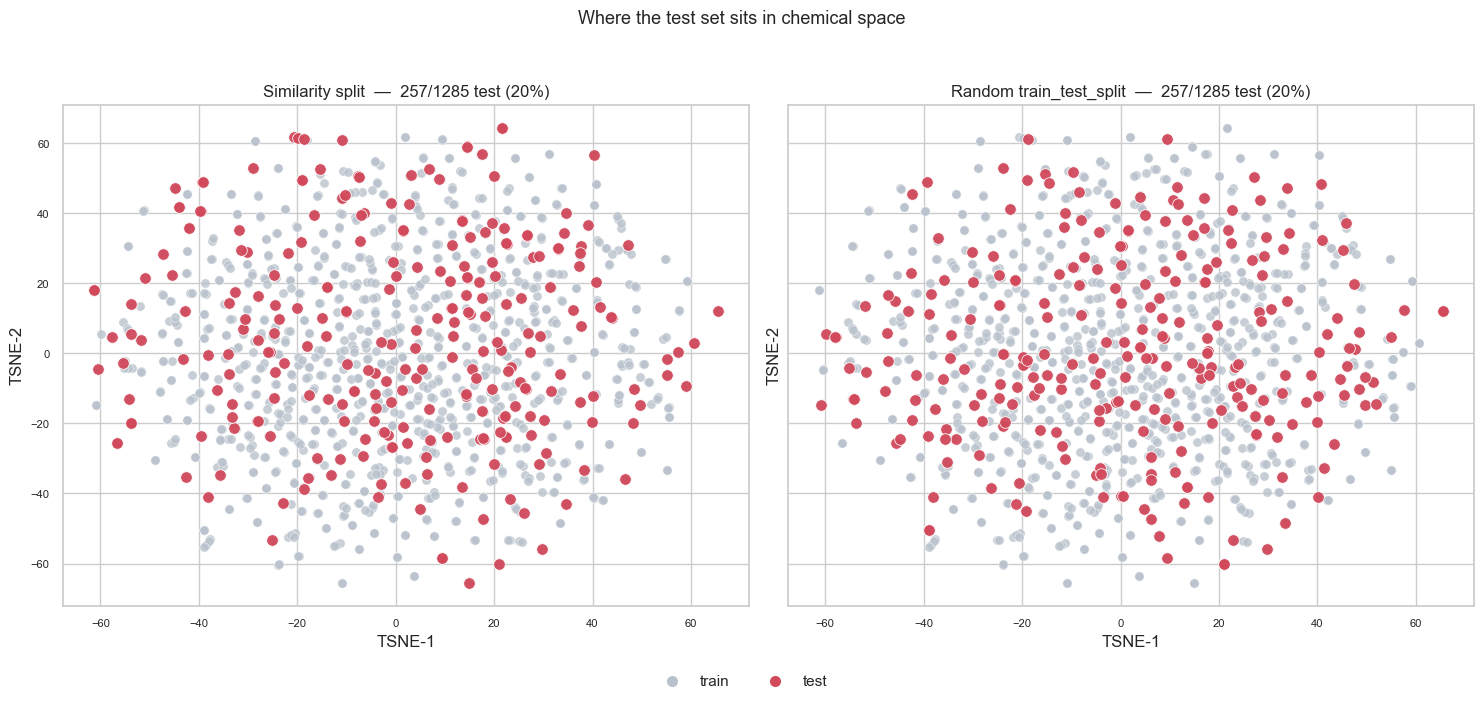

Cross-Validation Performance:
Training RMSE: 0.0906 (±0.0028)
Training R²: 0.9862 (±0.0008)
Validation RMSE: 0.6653 (±0.0187)
Validation R²: 0.2525 (±0.0575)

Final Test Performance:
RMSE: 0.7037
R²: 0.2579


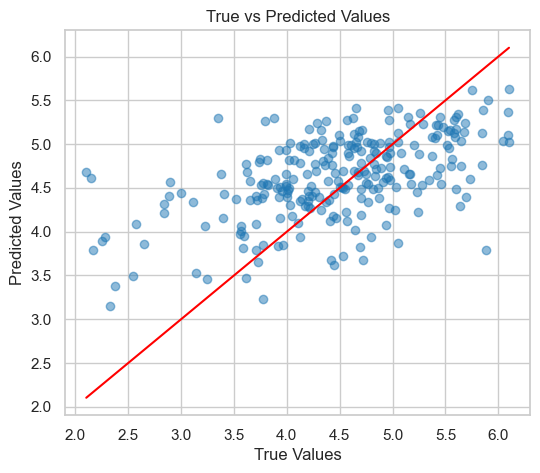

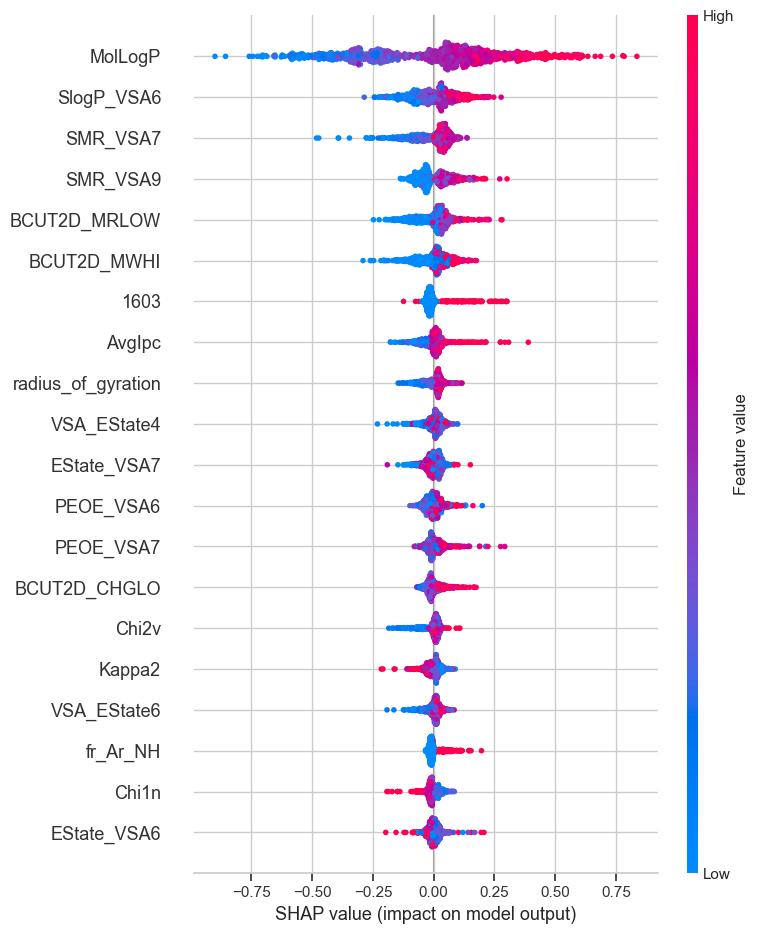

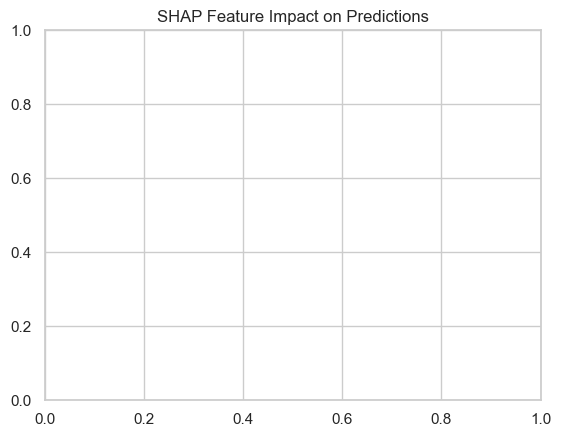



(1493, 2268)
Removing features with zero variance
(1493, 2250)
Removing feature with less then 0.1 correlation
(1493, 21)


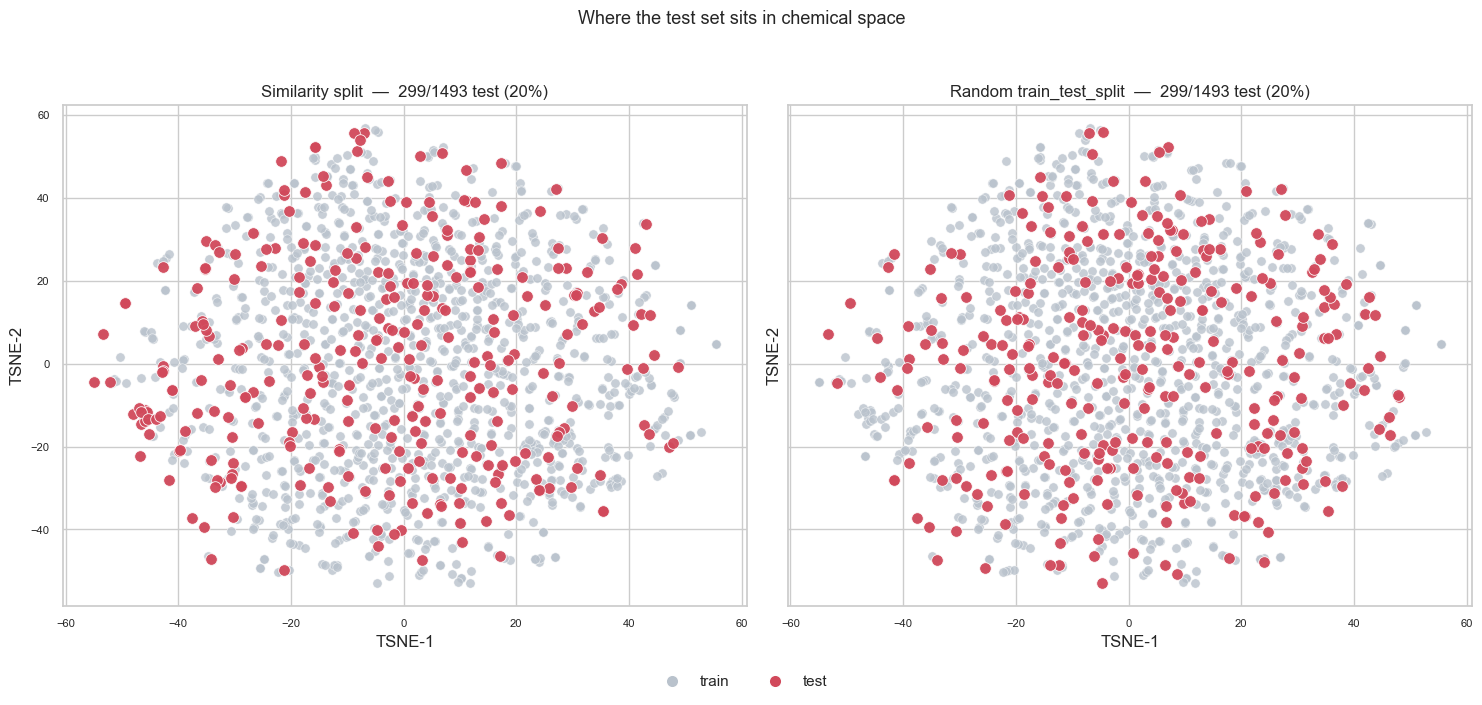

Cross-Validation Performance:
Training RMSE: 0.3544 (±0.0196)
Training R²: 0.8388 (±0.0156)
Validation RMSE: 0.8925 (±0.0690)
Validation R²: -0.0264 (±0.0319)

Final Test Performance:
RMSE: 0.9975
R²: 0.0514


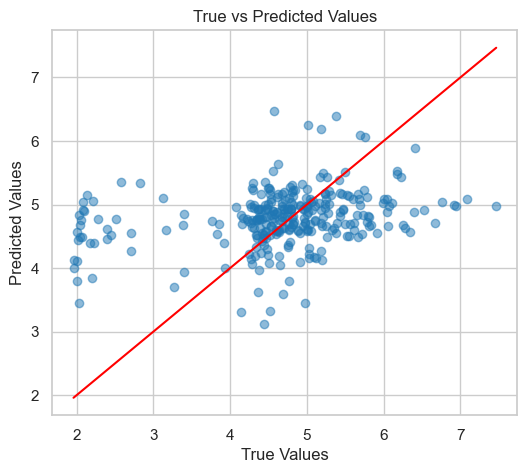

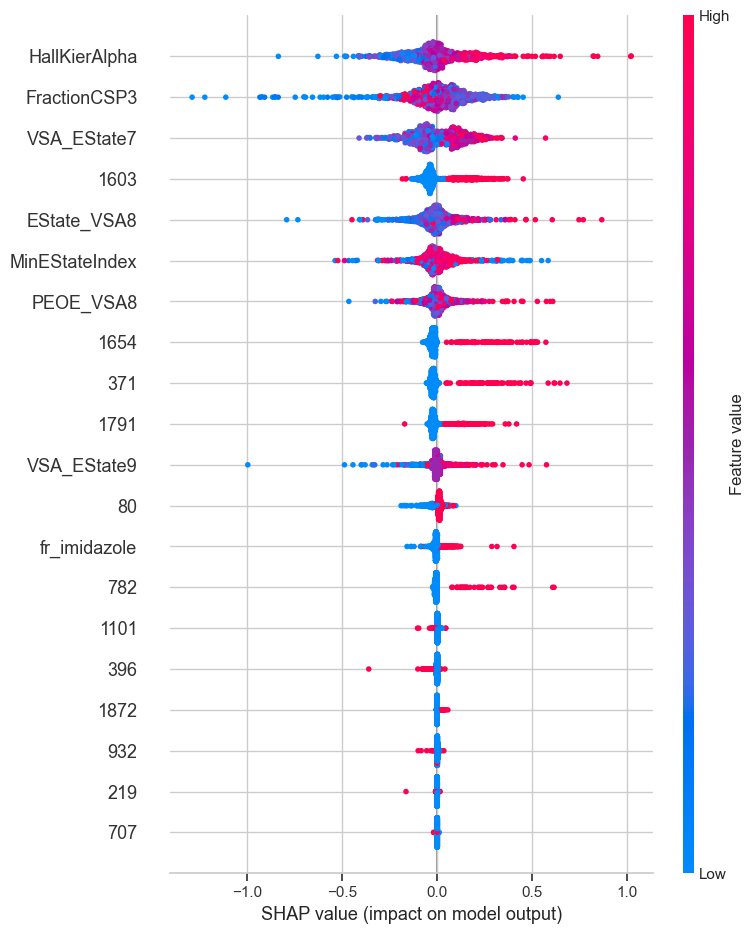

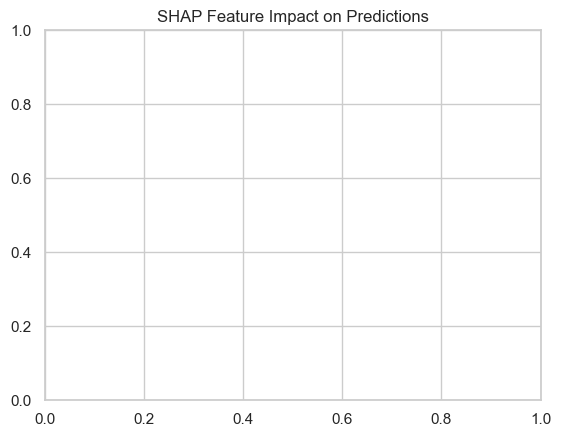



(2335, 2268)
Removing features with zero variance
(2335, 2250)
Removing feature with less then 0.1 correlation
(2335, 74)


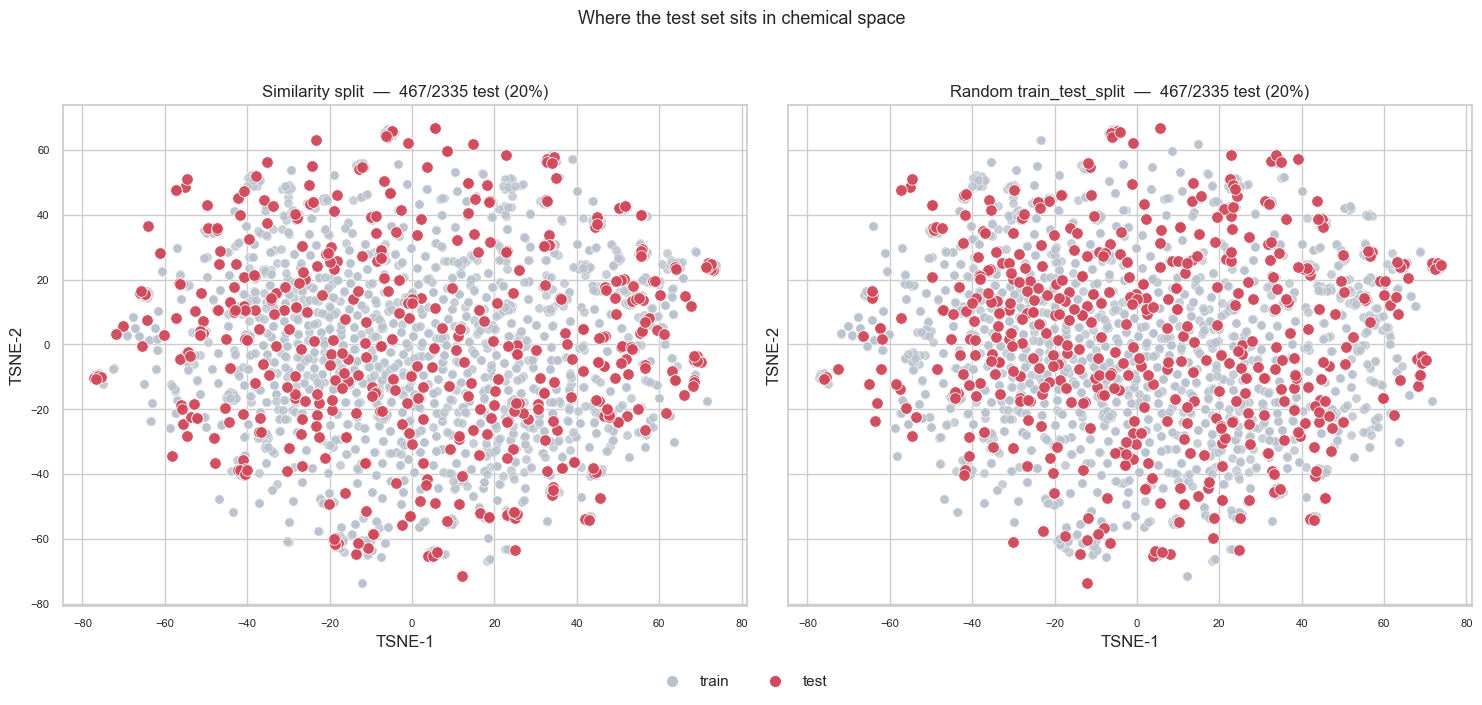

Cross-Validation Performance:
Training RMSE: 0.2088 (±0.0081)
Training R²: 0.9633 (±0.0028)
Validation RMSE: 0.7956 (±0.0213)
Validation R²: 0.4658 (±0.0397)

Final Test Performance:
RMSE: 0.7580
R²: 0.5238


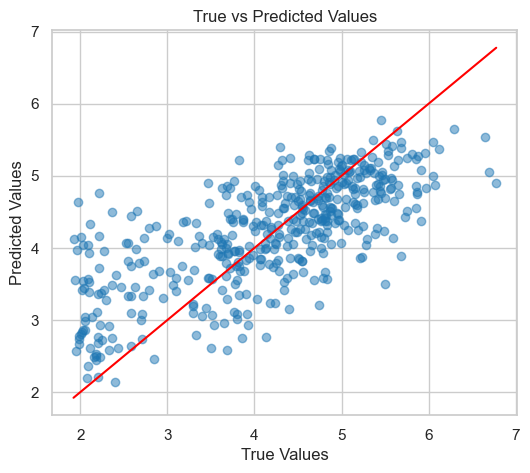

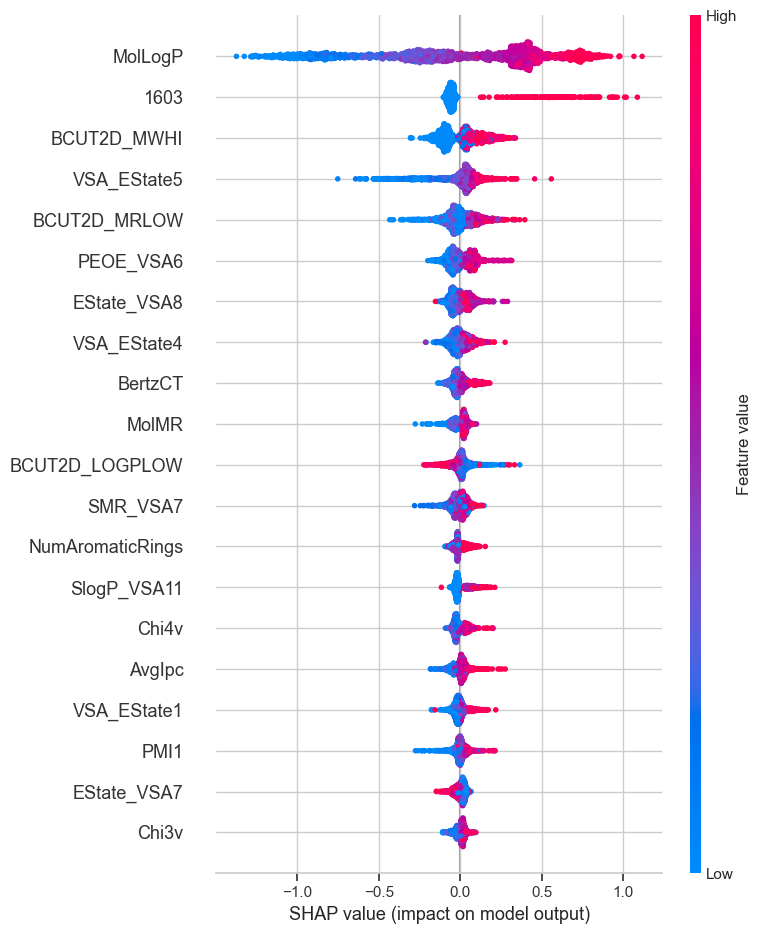

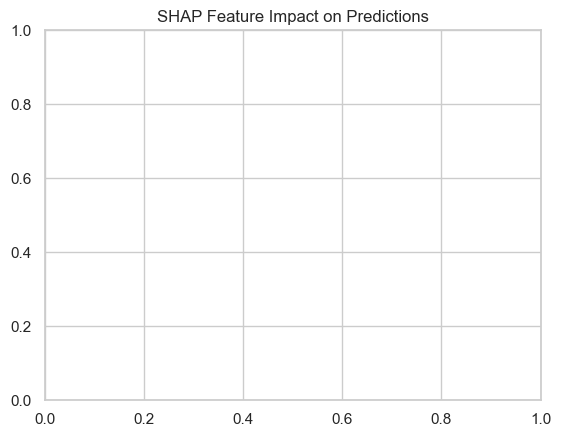

In [8]:
for i in CYP_ISOFORMS:
    cols = ["SMILES",f"{i}_pIC50_direct_inhibition"]    
    model_df = train_df[cols].copy()
    model_df.dropna(inplace=True)
    model_df = model_df.merge(train_feature_df,on="SMILES")
    model_df.drop("Molecule_Name",axis=1,inplace=True)
    model_df = model_df.merge(train_finderprint_df,on="SMILES")
    model_df.set_index("SMILES",inplace=True)
    smiles = model_df.index.to_list()
    print(model_df.shape)
    print("Removing features with zero variance")
    data = model_df.loc[:, model_df.var() !=0] 
    print(data.shape)
    print("Removing feature with less then 0.1 correlation")
    cor = data.corr()[f"{i}_pIC50_direct_inhibition"]
    data = data[cor[cor>0.1].index]
    print(data.shape)

    X = data.drop([f"{i}_pIC50_direct_inhibition"],axis=1)
    y =data[f"{i}_pIC50_direct_inhibition"].values
    
    X_train, X_test, y_train, y_test = similarity_train_test_split( X, y, smiles, test_size=0.2, random_state=42)
    scaler = StandardScaler().fit(X_train.values)
    X_train = pd.DataFrame(scaler.transform(X_train.values),  columns=X.columns)
    X_test = pd.DataFrame(scaler.transform(X_test.values), columns=X.columns)

    model = xgb.XGBRegressor(objective='reg:squarederror',  n_estimators=1000, learning_rate=0.01, random_state=42)
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    scoring = {'rmse': 'neg_root_mean_squared_error','r2': 'r2'}
    
    cv_results = cross_validate(model, X_train,y_train, cv=cv, scoring=scoring, return_train_score=True, return_estimator=True)
    
    train_rmse_mean = -cv_results['train_rmse'].mean()
    train_rmse_std = cv_results['train_rmse'].std()
    train_r2_mean = cv_results['train_r2'].mean()
    train_r2_std = cv_results['train_r2'].std()
    test_rmse_mean = -cv_results['test_rmse'].mean()
    test_rmse_std = cv_results['test_rmse'].std()
    test_r2_mean = cv_results['test_r2'].mean()
    test_r2_std = cv_results['test_r2'].std()
    
    print("Cross-Validation Performance:")
    print(f"Training RMSE: {train_rmse_mean:.4f} (±{train_rmse_std:.4f})")
    print(f"Training R²: {train_r2_mean:.4f} (±{train_r2_std:.4f})")
    print(f"Validation RMSE: {test_rmse_mean:.4f} (±{test_rmse_std:.4f})")
    print(f"Validation R²: {test_r2_mean:.4f} (±{test_r2_std:.4f})\n")
    
    model.fit(X_train, y_train)
    y_pred_test = model.predict(X_test)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    r2_test = r2_score(y_test, y_pred_test)
    
    print("Final Test Performance:")
    print(f"RMSE: {rmse_test:.4f}")
    print(f"R²: {r2_test:.4f}")  

    plt.figure(figsize=(6, 5))
    plt.scatter(y_test, y_pred_test, alpha=0.5)
    plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red')
    plt.xlabel("True Values")
    plt.ylabel("Predicted Values")
    plt.title("True vs Predicted Values")
    plt.show()
    explainer = shap.Explainer(model)
    shap_values = explainer(X_train)
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_train)
    plt.title("SHAP Feature Impact on Predictions")
    plt.show()
    print("\n")